In [1]:

import torch
import torchvision
import numpy as np
import matplotlib.pyplot as plt

print("PyTorch version:", torch.__version__)
print("Torchvision version:", torchvision.__version__)
print("NumPy version:", np.__version__)

if torch.cuda.is_available():
    print("GPU is available!")
    print("GPU name:", torch.cuda.get_device_name(0))
else:
    print("GPU is not available. Using CPU.")

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Current device:", device)


PyTorch version: 2.14.1+cu130
Torchvision version: 0.29.1+cu130
NumPy version: 2.4.6
GPU is available!
GPU name: Tesla T4
Current device: cuda


In [1]:

from google.colab import drive
drive.mount('/content/drive')

import os

PROJECT_DIR = "/content/drive/MyDrive/ResNet_CIFAR10"

DATA_DIR = os.path.join(PROJECT_DIR, "data")
RESULT_DIR = os.path.join(PROJECT_DIR, "results")
MODEL_DIR = os.path.join(PROJECT_DIR, "checkpoints")

for folder in [DATA_DIR, RESULT_DIR, MODEL_DIR]:
    os.makedirs(folder, exist_ok=True)

print("Project folders created!")
print("Project location:", PROJECT_DIR)


Mounted at /content/drive
Project folders created!
Project location: /content/drive/MyDrive/ResNet_CIFAR10


In [4]:

import torch
import torchvision
import torchvision.transforms as transforms

from torch.utils.data import DataLoader, random_split

# CIFAR-10 图像的标准化参数
mean = (0.4914, 0.4822, 0.4465)
std = (0.2470, 0.2435, 0.2616)

# 训练集数据增强
train_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])

# 验证集和测试集不进行随机增强
test_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])

# 下载训练数据
full_train_dataset = torchvision.datasets.CIFAR10(
    root=DATA_DIR,
    train=True,
    download=True,
    transform=train_transform
)

# 单独建立验证集，使用不带随机增强的转换
full_train_dataset_eval = torchvision.datasets.CIFAR10(
    root=DATA_DIR,
    train=True,
    download=False,
    transform=test_transform
)

# 固定随机种子，保证训练/验证划分可重复
generator = torch.Generator().manual_seed(42)

train_dataset, val_dataset = random_split(
    full_train_dataset,
    [45000, 5000],
    generator=generator
)

# 替换验证集的数据转换
val_dataset.dataset = full_train_dataset_eval

# 下载官方测试集
test_dataset = torchvision.datasets.CIFAR10(
    root=DATA_DIR,
    train=False,
    download=True,
    transform=test_transform
)

batch_size = 128

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=2
)

val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=2
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=2
)

print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Test samples:", len(test_dataset))


Training samples: 45000
Validation samples: 5000
Test samples: 10000


In [3]:

from google.colab import drive
drive.mount('/content/drive')

import os

PROJECT_DIR = "/content/drive/MyDrive/ResNet_CIFAR10"

DATA_DIR = os.path.join(PROJECT_DIR, "data")
RESULT_DIR = os.path.join(PROJECT_DIR, "results")
MODEL_DIR = os.path.join(PROJECT_DIR, "checkpoints")

for folder in [DATA_DIR, RESULT_DIR, MODEL_DIR]:
    os.makedirs(folder, exist_ok=True)

print("Project folders created!")
print("DATA_DIR:", DATA_DIR)


Mounted at /content/drive
Project folders created!
DATA_DIR: /content/drive/MyDrive/ResNet_CIFAR10/data


In [5]:

import os

backup_name = "ResNet_CIFAR10_Project_Backup.ipynb"
drive_path = "/content/drive/MyDrive"

found = []

for root, dirs, files in os.walk(drive_path):
    if backup_name in files:
        found.append(os.path.join(root, backup_name))

if found:
    print("备份文件已经找到！")
    for path in found:
        print(path)
else:
    print("暂时没有找到备份文件。")


备份文件已经找到！
/content/drive/MyDrive/Colab Notebooks/ResNet_CIFAR10_Project_Backup.ipynb


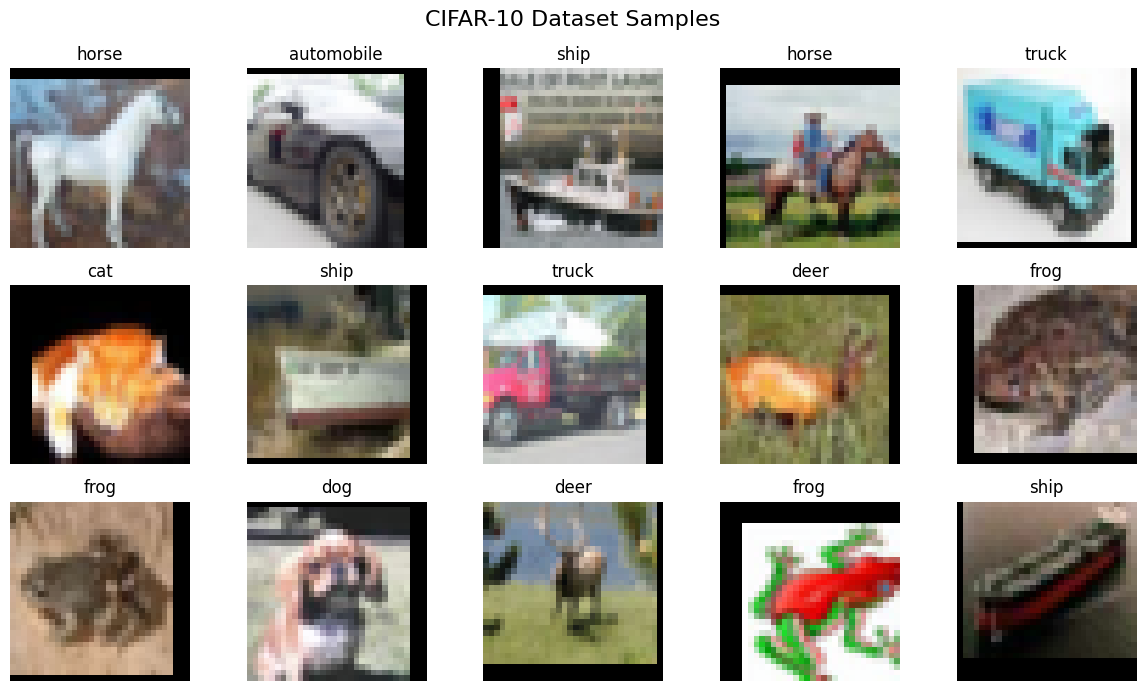

图片已保存到： /content/drive/MyDrive/ResNet_CIFAR10/results/cifar10_samples.png


In [6]:

import matplotlib.pyplot as plt
import numpy as np

# CIFAR-10 的类别名称
classes = [
    'airplane', 'automobile', 'bird', 'cat', 'deer',
    'dog', 'frog', 'horse', 'ship', 'truck'
]

# 从训练集中取出一个批次
images, labels = next(iter(train_loader))

# 反标准化，恢复图片原本的颜色
mean = np.array([0.4914, 0.4822, 0.4465])
std = np.array([0.2470, 0.2435, 0.2616])

fig, axes = plt.subplots(3, 5, figsize=(12, 7))

for i, ax in enumerate(axes.flat):
    img = images[i].numpy().transpose(1, 2, 0)
    img = img * std + mean
    img = np.clip(img, 0, 1)

    ax.imshow(img)
    ax.set_title(classes[labels[i].item()])
    ax.axis('off')

plt.suptitle('CIFAR-10 Dataset Samples', fontsize=16)
plt.tight_layout()

# 保存图片到 Google Drive
sample_path = os.path.join(RESULT_DIR, "cifar10_samples.png")
plt.savefig(sample_path, dpi=300, bbox_inches='tight')

plt.show()

print("图片已保存到：", sample_path)


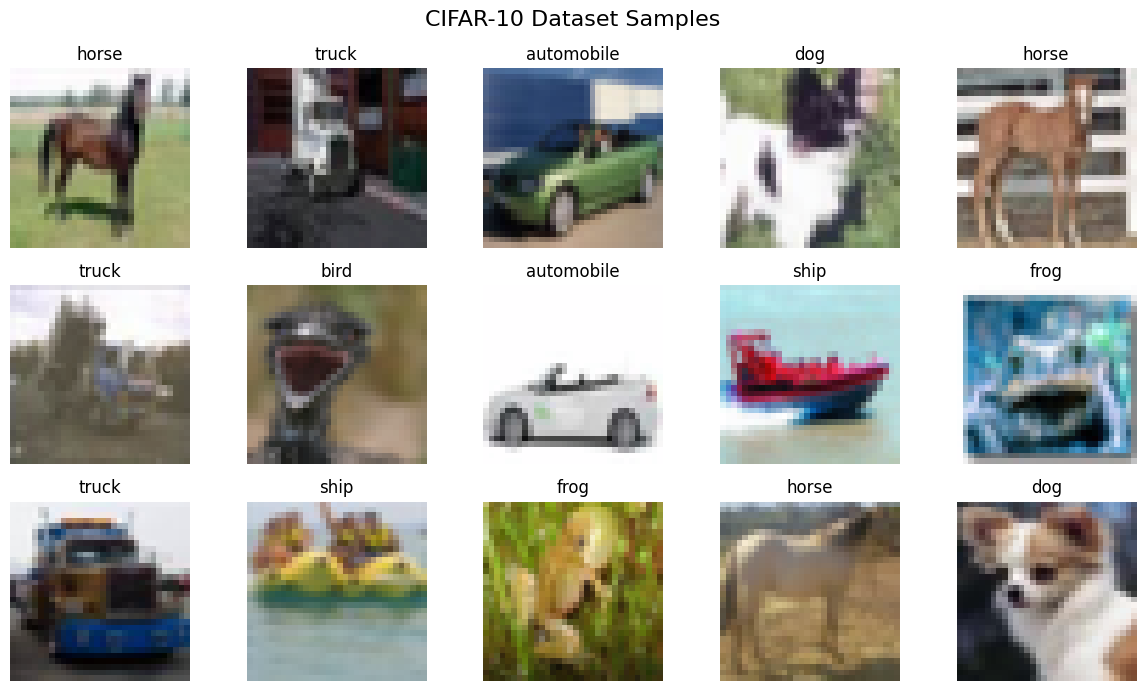

清晰版图片已保存： /content/drive/MyDrive/ResNet_CIFAR10/results/cifar10_samples_clean.png


In [7]:

import matplotlib.pyplot as plt
import numpy as np

classes = [
    'airplane', 'automobile', 'bird', 'cat', 'deer',
    'dog', 'frog', 'horse', 'ship', 'truck'
]

# 从验证集中取出图片，不使用随机裁剪
fig, axes = plt.subplots(3, 5, figsize=(12, 7))

for i, ax in enumerate(axes.flat):
    img, label = val_dataset[i]

    # 反标准化
    img = img.numpy().transpose(1, 2, 0)
    img = img * np.array([0.2470, 0.2435, 0.2616]) \
          + np.array([0.4914, 0.4822, 0.4465])
    img = np.clip(img, 0, 1)

    ax.imshow(img, interpolation='nearest')
    ax.set_title(classes[label])
    ax.axis('off')

plt.suptitle('CIFAR-10 Dataset Samples', fontsize=16)
plt.tight_layout()

sample_path = os.path.join(
    RESULT_DIR, "cifar10_samples_clean.png"
)

plt.savefig(sample_path, dpi=300, bbox_inches='tight')
plt.show()

print("清晰版图片已保存：", sample_path)


In [10]:

import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("当前运行设备：", device)

if torch.cuda.is_available():
    print("GPU 型号：", torch.cuda.get_device_name(0))
else:
    print("当前使用 CPU")


当前运行设备： cuda
GPU 型号： Tesla T4


In [11]:

import torch
import torch.nn as nn
import torch.nn.functional as F

# 普通 CNN 对照模型
class BaselineCNN(nn.Module):
    def __init__(self, num_classes=10):
        super(BaselineCNN, self).__init__()

        self.conv1 = nn.Conv2d(3, 32, kernel_size=3, padding=1)
        self.bn1 = nn.BatchNorm2d(32)

        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.bn2 = nn.BatchNorm2d(64)

        self.conv3 = nn.Conv2d(64, 128, kernel_size=3, padding=1)
        self.bn3 = nn.BatchNorm2d(128)

        self.pool = nn.MaxPool2d(2, 2)
        self.avgpool = nn.AdaptiveAvgPool2d((1, 1))
        self.fc = nn.Linear(128, num_classes)

    def forward(self, x):
        x = F.relu(self.bn1(self.conv1(x)))
        x = self.pool(x)

        x = F.relu(self.bn2(self.conv2(x)))
        x = self.pool(x)

        x = F.relu(self.bn3(self.conv3(x)))

        x = self.avgpool(x)
        x = torch.flatten(x, 1)

        return self.fc(x)


# 创建模型并放到 GPU 或 CPU
baseline_model = BaselineCNN().to(device)

# 查看模型结构
print(baseline_model)

# 检查输入和输出维度
sample_images, sample_labels = next(iter(train_loader))
sample_images = sample_images.to(device)

with torch.no_grad():
    outputs = baseline_model(sample_images)

print("输入图片尺寸：", sample_images.shape)
print("模型输出尺寸：", outputs.shape)
print("模型创建成功！")


BaselineCNN(
  (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (conv3): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn3): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (avgpool): AdaptiveAvgPool2d(output_size=(1, 1))
  (fc): Linear(in_features=128, out_features=10, bias=True)
)
输入图片尺寸： torch.Size([128, 3, 32, 32])
模型输出尺寸： torch.Size([128, 10])
模型创建成功！


Epoch [1/10] Train Loss: 1.6890 Train Acc: 38.08% Val Loss: 1.5170 Val Acc: 46.12%
Epoch [2/10] Train Loss: 1.3550 Train Acc: 51.39% Val Loss: 1.4028 Val Acc: 49.44%
Epoch [3/10] Train Loss: 1.2368 Train Acc: 55.82% Val Loss: 1.3244 Val Acc: 52.70%
Epoch [4/10] Train Loss: 1.1702 Train Acc: 58.49% Val Loss: 1.1398 Val Acc: 59.78%
Epoch [5/10] Train Loss: 1.1121 Train Acc: 60.60% Val Loss: 1.1152 Val Acc: 60.50%
Epoch [6/10] Train Loss: 1.0648 Train Acc: 62.42% Val Loss: 1.2495 Val Acc: 56.56%
Epoch [7/10] Train Loss: 1.0260 Train Acc: 63.99% Val Loss: 1.0582 Val Acc: 62.58%
Epoch [8/10] Train Loss: 0.9415 Train Acc: 67.67% Val Loss: 0.9302 Val Acc: 67.22%
Epoch [9/10] Train Loss: 0.9217 Train Acc: 68.17% Val Loss: 0.9358 Val Acc: 66.60%
Epoch [10/10] Train Loss: 0.9144 Train Acc: 68.05% Val Loss: 0.9195 Val Acc: 67.48%


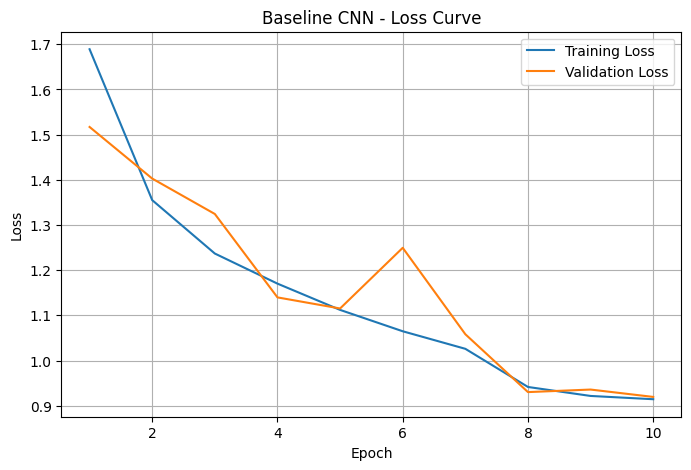

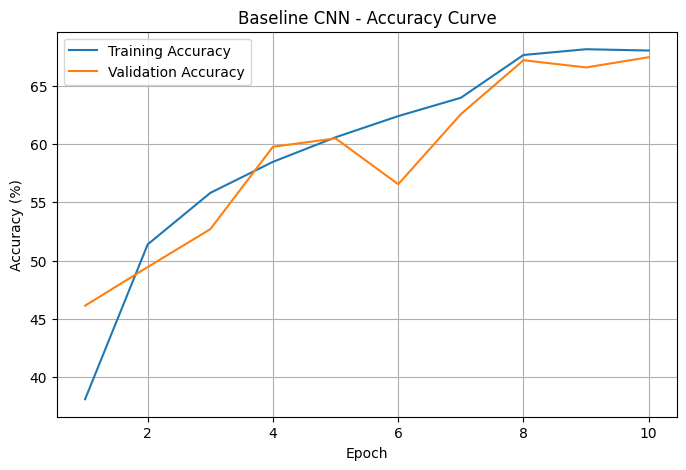

普通 CNN 训练完成！
最佳验证集准确率： 67.48 %
训练日志： /content/drive/MyDrive/ResNet_CIFAR10/results/baseline_training_log.csv
模型权重： /content/drive/MyDrive/ResNet_CIFAR10/checkpoints/baseline_best.pth


In [12]:

import os
import csv
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

# 确保保存目录存在
os.makedirs(RESULT_DIR, exist_ok=True)
os.makedirs(MODEL_DIR, exist_ok=True)

# 重新初始化模型，确保从头开始训练
baseline_model = BaselineCNN().to(device)

criterion = nn.CrossEntropyLoss()

optimizer = optim.SGD(
    baseline_model.parameters(),
    lr=0.01,
    momentum=0.9,
    weight_decay=5e-4
)

scheduler = optim.lr_scheduler.StepLR(
    optimizer, step_size=7, gamma=0.1
)

# 训练和验证函数
def run_epoch(model, loader, training=True):
    if training:
        model.train()
    else:
        model.eval()

    total_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)

        if training:
            optimizer.zero_grad()

        with torch.set_grad_enabled(training):
            outputs = model(images)
            loss = criterion(outputs, labels)

            if training:
                loss.backward()
                optimizer.step()

        total_loss += loss.item() * images.size(0)
        _, predicted = outputs.max(1)
        total += labels.size(0)
        correct += predicted.eq(labels).sum().item()

    return total_loss / total, 100.0 * correct / total


# 正式训练10轮
EPOCHS = 10

history = {
    "train_loss": [],
    "val_loss": [],
    "train_acc": [],
    "val_acc": []
}

best_val_acc = 0.0

for epoch in range(EPOCHS):
    train_loss, train_acc = run_epoch(
        baseline_model, train_loader, training=True
    )

    val_loss, val_acc = run_epoch(
        baseline_model, val_loader, training=False
    )

    scheduler.step()

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_acc"].append(train_acc)
    history["val_acc"].append(val_acc)

    print(
        f"Epoch [{epoch+1}/{EPOCHS}] "
        f"Train Loss: {train_loss:.4f} "
        f"Train Acc: {train_acc:.2f}% "
        f"Val Loss: {val_loss:.4f} "
        f"Val Acc: {val_acc:.2f}%"
    )

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(
            baseline_model.state_dict(),
            os.path.join(MODEL_DIR, "baseline_best.pth")
        )

# 保存训练日志
csv_path = os.path.join(RESULT_DIR, "baseline_training_log.csv")

with open(csv_path, "w", newline="") as f:
    writer = csv.writer(f)
    writer.writerow([
        "epoch", "train_loss", "val_loss",
        "train_accuracy", "val_accuracy"
    ])

    for i in range(EPOCHS):
        writer.writerow([
            i + 1,
            history["train_loss"][i],
            history["val_loss"][i],
            history["train_acc"][i],
            history["val_acc"][i]
        ])

# 绘制损失曲线
plt.figure(figsize=(8, 5))
plt.plot(range(1, EPOCHS+1), history["train_loss"], label="Training Loss")
plt.plot(range(1, EPOCHS+1), history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Baseline CNN - Loss Curve")
plt.legend()
plt.grid(True)
plt.savefig(
    os.path.join(RESULT_DIR, "baseline_loss.png"),
    dpi=300, bbox_inches="tight"
)
plt.show()

# 绘制准确率曲线
plt.figure(figsize=(8, 5))
plt.plot(range(1, EPOCHS+1), history["train_acc"], label="Training Accuracy")
plt.plot(range(1, EPOCHS+1), history["val_acc"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("Baseline CNN - Accuracy Curve")
plt.legend()
plt.grid(True)
plt.savefig(
    os.path.join(RESULT_DIR, "baseline_accuracy.png"),
    dpi=300, bbox_inches="tight"
)
plt.show()

print("普通 CNN 训练完成！")
print("最佳验证集准确率：", round(best_val_acc, 2), "%")
print("训练日志：", csv_path)
print("模型权重：", os.path.join(MODEL_DIR, "baseline_best.pth"))


In [13]:
import os

baseline_weight = os.path.join(
    MODEL_DIR, "baseline_best.pth"
)

baseline_log = os.path.join(
    RESULT_DIR, "baseline_training_log.csv"
)

print("模型权重是否存在：", os.path.exists(baseline_weight))
print("训练日志是否存在：", os.path.exists(baseline_log))

if os.path.exists(baseline_weight):
    print("模型权重大小：", os.path.getsize(baseline_weight) / 1024 / 1024, "MB")

if os.path.exists(baseline_log):
    print("训练日志大小：", os.path.getsize(baseline_log), "字节")

模型权重是否存在： True
训练日志是否存在： True
模型权重大小： 0.3716545104980469 MB
训练日志大小： 702 字节


In [14]:
import torch
import torch.nn as nn
import torch.nn.functional as F


# ResNet 的残差模块
class BasicBlock(nn.Module):
    expansion = 1

    def __init__(self, in_channels, out_channels, stride=1):
        super(BasicBlock, self).__init__()

        self.conv1 = nn.Conv2d(
            in_channels, out_channels,
            kernel_size=3, stride=stride,
            padding=1, bias=False
        )
        self.bn1 = nn.BatchNorm2d(out_channels)

        self.conv2 = nn.Conv2d(
            out_channels, out_channels,
            kernel_size=3, stride=1,
            padding=1, bias=False
        )
        self.bn2 = nn.BatchNorm2d(out_channels)

        # 当输入输出尺寸不同时，调整残差分支
        if stride != 1 or in_channels != out_channels:
            self.shortcut = nn.Sequential(
                nn.Conv2d(
                    in_channels, out_channels,
                    kernel_size=1, stride=stride,
                    bias=False
                ),
                nn.BatchNorm2d(out_channels)
            )
        else:
            self.shortcut = nn.Identity()

    def forward(self, x):
        identity = self.shortcut(x)

        out = F.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))

        out = out + identity
        out = F.relu(out)

        return out


# ResNet-20 网络
class ResNet20(nn.Module):
    def __init__(self, num_classes=10):
        super(ResNet20, self).__init__()

        self.in_channels = 16

        self.conv1 = nn.Conv2d(
            3, 16, kernel_size=3,
            stride=1, padding=1, bias=False
        )
        self.bn1 = nn.BatchNorm2d(16)

        self.layer1 = self.make_layer(16, 3, stride=1)
        self.layer2 = self.make_layer(32, 3, stride=2)
        self.layer3 = self.make_layer(64, 3, stride=2)

        self.avgpool = nn.AdaptiveAvgPool2d((1, 1))
        self.fc = nn.Linear(64, num_classes)

    def make_layer(self, out_channels, blocks, stride):
        layers = []

        layers.append(
            BasicBlock(self.in_channels, out_channels, stride)
        )

        self.in_channels = out_channels

        for _ in range(1, blocks):
            layers.append(
                BasicBlock(self.in_channels, out_channels)
            )

        return nn.Sequential(*layers)

    def forward(self, x):
        x = F.relu(self.bn1(self.conv1(x)))

        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)

        x = self.avgpool(x)
        x = torch.flatten(x, 1)

        x = self.fc(x)

        return x


# 创建模型
resnet_model = ResNet20().to(device)

# 查看模型结构
print(resnet_model)

# 检查输入输出维度
sample_images, sample_labels = next(iter(train_loader))
sample_images = sample_images.to(device)

with torch.no_grad():
    outputs = resnet_model(sample_images)

print("输入图片尺寸：", sample_images.shape)
print("模型输出尺寸：", outputs.shape)
print("ResNet-20 模型创建成功！")

ResNet20(
  (conv1): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
  (bn1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(16, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (conv2): Conv2d(16, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (shortcut): Identity()
    )
    (1): BasicBlock(
      (conv1): Conv2d(16, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (conv2): Conv2d(16, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): Batc

开始训练 ResNet-20 ...
Epoch [1/20] Train Loss: 1.6016 Train Acc: 39.67% Val Loss: 1.2690 Val Acc: 52.68%
Epoch [2/20] Train Loss: 1.1339 Train Acc: 58.55% Val Loss: 1.1420 Val Acc: 59.60%
Epoch [3/20] Train Loss: 0.9263 Train Acc: 67.04% Val Loss: 1.3178 Val Acc: 57.90%
Epoch [4/20] Train Loss: 0.8044 Train Acc: 71.60% Val Loss: 0.8486 Val Acc: 70.62%
Epoch [5/20] Train Loss: 0.7216 Train Acc: 74.62% Val Loss: 0.8235 Val Acc: 71.46%
Epoch [6/20] Train Loss: 0.6576 Train Acc: 77.05% Val Loss: 0.6599 Val Acc: 76.18%
Epoch [7/20] Train Loss: 0.6202 Train Acc: 78.38% Val Loss: 0.8114 Val Acc: 71.02%
Epoch [8/20] Train Loss: 0.5772 Train Acc: 80.02% Val Loss: 0.6526 Val Acc: 77.36%
Epoch [9/20] Train Loss: 0.5529 Train Acc: 80.82% Val Loss: 0.6202 Val Acc: 79.10%
Epoch [10/20] Train Loss: 0.5236 Train Acc: 81.84% Val Loss: 0.6158 Val Acc: 79.26%
Epoch [11/20] Train Loss: 0.4358 Train Acc: 85.01% Val Loss: 0.4483 Val Acc: 84.68%
Epoch [12/20] Train Loss: 0.4082 Train Acc: 85.98% Val Loss: 0.444

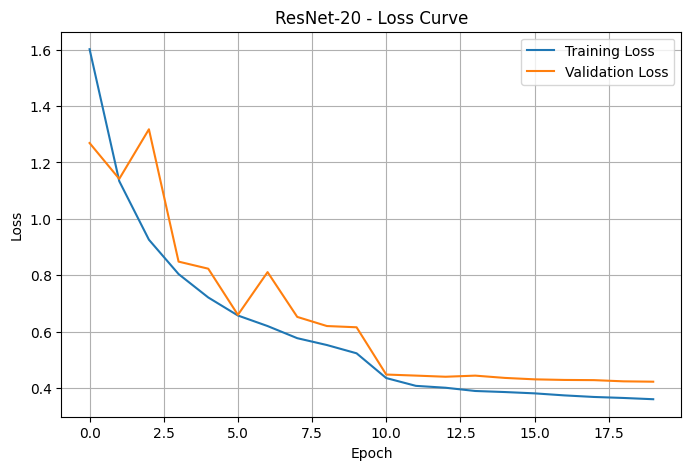

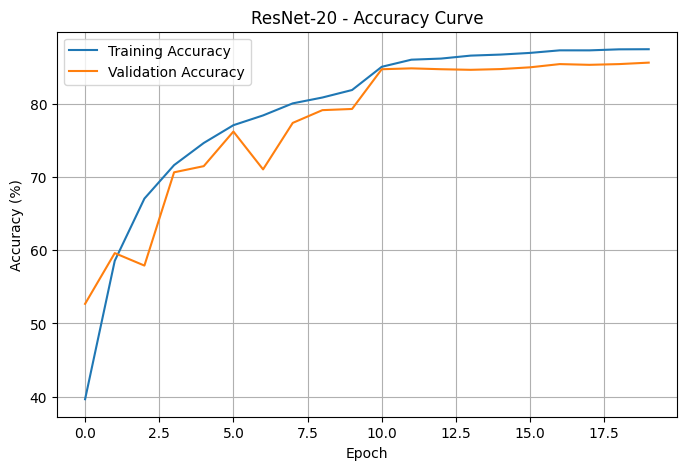


ResNet-20 训练完成！
最佳验证集准确率：85.58%
模型权重： /content/drive/MyDrive/ResNet_CIFAR10/checkpoints/resnet20_best.pth
训练日志： /content/drive/MyDrive/ResNet_CIFAR10/results/resnet20_training_log.csv


In [15]:

import os
import csv
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

# 确保保存目录存在
os.makedirs(RESULT_DIR, exist_ok=True)
os.makedirs(MODEL_DIR, exist_ok=True)

# 固定随机种子
torch.manual_seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

# 重新创建模型，从头开始训练
resnet_model = ResNet20().to(device)

criterion = nn.CrossEntropyLoss()

optimizer = optim.SGD(
    resnet_model.parameters(),
    lr=0.01,
    momentum=0.9,
    weight_decay=5e-4
)

scheduler = optim.lr_scheduler.StepLR(
    optimizer, step_size=10, gamma=0.1
)

# 训练一个 epoch
def train_resnet_epoch(model, loader):
    model.train()
    total_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * images.size(0)
        predicted = outputs.argmax(dim=1)
        correct += (predicted == labels).sum().item()
        total += labels.size(0)

    return total_loss / total, 100.0 * correct / total


# 验证一个 epoch
def validate_resnet_epoch(model, loader):
    model.eval()
    total_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            total_loss += loss.item() * images.size(0)
            predicted = outputs.argmax(dim=1)
            correct += (predicted == labels).sum().item()
            total += labels.size(0)

    return total_loss / total, 100.0 * correct / total


# 记录训练过程
history = {
    "train_loss": [],
    "val_loss": [],
    "train_acc": [],
    "val_acc": []
}

best_val_acc = 0.0
best_model_path = os.path.join(MODEL_DIR, "resnet20_best.pth")
log_path = os.path.join(RESULT_DIR, "resnet20_training_log.csv")

epochs = 20

print("开始训练 ResNet-20 ...")

for epoch in range(epochs):
    train_loss, train_acc = train_resnet_epoch(
        resnet_model, train_loader
    )

    val_loss, val_acc = validate_resnet_epoch(
        resnet_model, val_loader
    )

    scheduler.step()

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_acc"].append(train_acc)
    history["val_acc"].append(val_acc)

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(resnet_model.state_dict(), best_model_path)

    print(
        f"Epoch [{epoch+1}/{epochs}] "
        f"Train Loss: {train_loss:.4f} "
        f"Train Acc: {train_acc:.2f}% "
        f"Val Loss: {val_loss:.4f} "
        f"Val Acc: {val_acc:.2f}%"
    )

# 保存训练日志
with open(log_path, "w", newline="") as f:
    writer = csv.writer(f)
    writer.writerow([
        "epoch", "train_loss", "val_loss",
        "train_acc", "val_acc"
    ])

    for i in range(epochs):
        writer.writerow([
            i + 1,
            history["train_loss"][i],
            history["val_loss"][i],
            history["train_acc"][i],
            history["val_acc"][i]
        ])

# 绘制损失曲线
plt.figure(figsize=(8, 5))
plt.plot(history["train_loss"], label="Training Loss")
plt.plot(history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("ResNet-20 - Loss Curve")
plt.legend()
plt.grid(True)
plt.savefig(
    os.path.join(RESULT_DIR, "resnet20_loss.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# 绘制准确率曲线
plt.figure(figsize=(8, 5))
plt.plot(history["train_acc"], label="Training Accuracy")
plt.plot(history["val_acc"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("ResNet-20 - Accuracy Curve")
plt.legend()
plt.grid(True)
plt.savefig(
    os.path.join(RESULT_DIR, "resnet20_accuracy.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("\nResNet-20 训练完成！")
print(f"最佳验证集准确率：{best_val_acc:.2f}%")
print("模型权重：", best_model_path)
print("训练日志：", log_path)


========== ResNet-20 官方测试集结果 ==========
测试集图片数量： 10000
测试集 Loss：0.4481
测试集 Accuracy：84.93%

========== 分类报告 ==========
              precision    recall  f1-score   support

    airplane     0.8315    0.8830    0.8565      1000
  automobile     0.9470    0.9290    0.9379      1000
        bird     0.7890    0.7890    0.7890      1000
         cat     0.7300    0.7030    0.7163      1000
        deer     0.8178    0.8440    0.8307      1000
         dog     0.7750    0.7680    0.7715      1000
        frog     0.8769    0.8760    0.8764      1000
       horse     0.9128    0.8480    0.8792      1000
        ship     0.8922    0.9440    0.9174      1000
       truck     0.9228    0.9090    0.9159      1000

    accuracy                         0.8493     10000
   macro avg     0.8495    0.8493    0.8491     10000
weighted avg     0.8495    0.8493    0.8491     10000



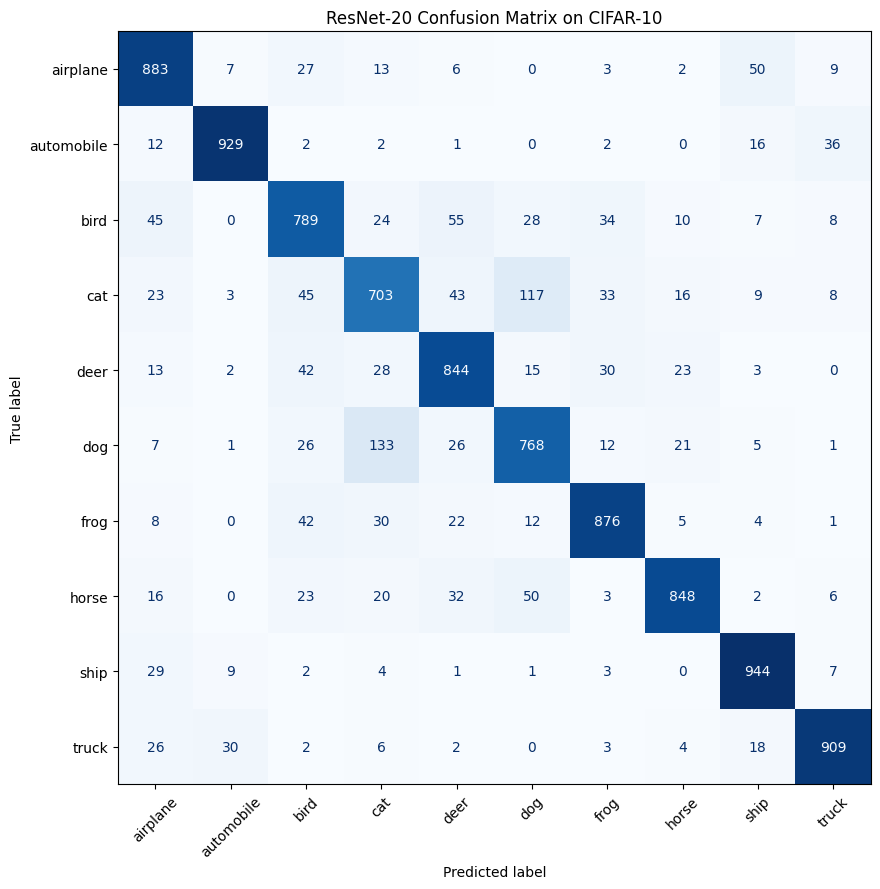


测试结果和混淆矩阵已保存！
测试结果： /content/drive/MyDrive/ResNet_CIFAR10/results/resnet20_test_result.csv
分类报告： /content/drive/MyDrive/ResNet_CIFAR10/results/resnet20_classification_report.txt
混淆矩阵： /content/drive/MyDrive/ResNet_CIFAR10/results/resnet20_confusion_matrix.png


In [16]:

import os
import csv
import torch
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

# CIFAR-10 的类别名称
class_names = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck"
]

# 加载训练过程中保存的最佳模型
best_model_path = os.path.join(
    MODEL_DIR, "resnet20_best.pth"
)

resnet_model = ResNet20().to(device)

try:
    state_dict = torch.load(
        best_model_path,
        map_location=device,
        weights_only=True
    )
except TypeError:
    state_dict = torch.load(
        best_model_path,
        map_location=device
    )

resnet_model.load_state_dict(state_dict)
resnet_model.eval()

# 在官方测试集上进行预测
all_labels = []
all_predictions = []
test_loss = 0.0
correct = 0
total = 0

criterion = torch.nn.CrossEntropyLoss()

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = resnet_model(images)
        loss = criterion(outputs, labels)

        predictions = outputs.argmax(dim=1)

        test_loss += loss.item() * images.size(0)
        correct += (predictions == labels).sum().item()
        total += labels.size(0)

        all_labels.extend(labels.cpu().numpy())
        all_predictions.extend(predictions.cpu().numpy())

test_loss = test_loss / total
test_accuracy = 100.0 * correct / total

print("========== ResNet-20 官方测试集结果 ==========")
print("测试集图片数量：", total)
print(f"测试集 Loss：{test_loss:.4f}")
print(f"测试集 Accuracy：{test_accuracy:.2f}%")

# 保存测试结果
test_result_path = os.path.join(
    RESULT_DIR, "resnet20_test_result.csv"
)

with open(test_result_path, "w", newline="") as f:
    writer = csv.writer(f)
    writer.writerow(["Metric", "Value"])
    writer.writerow(["Test Loss", test_loss])
    writer.writerow(["Test Accuracy (%)", test_accuracy])

# 输出分类报告
report = classification_report(
    all_labels,
    all_predictions,
    target_names=class_names,
    digits=4
)

print("\n========== 分类报告 ==========")
print(report)

# 保存分类报告
report_path = os.path.join(
    RESULT_DIR, "resnet20_classification_report.txt"
)

with open(report_path, "w") as f:
    f.write(report)

# 绘制混淆矩阵
cm = confusion_matrix(all_labels, all_predictions)

fig, ax = plt.subplots(figsize=(10, 9))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot(
    ax=ax,
    cmap="Blues",
    xticks_rotation=45,
    values_format="d",
    colorbar=False
)

plt.title("ResNet-20 Confusion Matrix on CIFAR-10")
plt.tight_layout()

cm_path = os.path.join(
    RESULT_DIR, "resnet20_confusion_matrix.png"
)

plt.savefig(cm_path, dpi=300, bbox_inches="tight")
plt.show()

print("\n测试结果和混淆矩阵已保存！")
print("测试结果：", test_result_path)
print("分类报告：", report_path)
print("混淆矩阵：", cm_path)


In [17]:

# 检查当前生成的混淆矩阵
import numpy as np
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    all_labels,
    all_predictions
)

print("混淆矩阵形状：", cm.shape)
print("所有元素总和：", cm.sum())
print("对角线总和：", np.trace(cm))
print("各行总和：", cm.sum(axis=1))
print("对角线数值：", np.diag(cm))

# 自动检查
assert cm.shape == (10, 10)
assert cm.sum() == 10000
assert np.trace(cm) == 8493
assert np.all(cm.sum(axis=1) == 1000)

print("\n混淆矩阵检查通过！")


混淆矩阵形状： (10, 10)
所有元素总和： 10000
对角线总和： 8493
各行总和： [1000 1000 1000 1000 1000 1000 1000 1000 1000 1000]
对角线数值： [883 929 789 703 844 768 876 848 944 909]

混淆矩阵检查通过！


In [18]:
import torch
import torch.nn as nn
import torch.optim as optim
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
import os

# 固定随机种子，便于复现实验
torch.manual_seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

# 创建新的 BaselineCNN 模型
baseline20 = BaselineCNN().to(device)

# 与 ResNet-20 使用相同的主要优化设置
criterion = nn.CrossEntropyLoss()

optimizer = optim.SGD(
    baseline20.parameters(),
    lr=0.01,
    momentum=0.9,
    weight_decay=5e-4
)

# 与 ResNet-20 一样，在第 10 个 epoch 后调整学习率
scheduler = optim.lr_scheduler.StepLR(
    optimizer,
    step_size=10,
    gamma=0.1
)

EPOCHS = 20
best_val_acc = 0.0
history_baseline20 = []

for epoch in range(EPOCHS):
    # ---------- 训练 ----------
    baseline20.train()
    train_loss = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in tqdm(
        train_loader,
        desc=f"Epoch {epoch+1}/{EPOCHS}"
    ):
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()
        outputs = baseline20(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        train_loss += loss.item() * images.size(0)
        _, predicted = outputs.max(1)
        train_total += labels.size(0)
        train_correct += predicted.eq(labels).sum().item()

    train_loss /= train_total
    train_acc = 100.0 * train_correct / train_total

    # ---------- 验证 ----------
    baseline20.eval()
    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = baseline20(images)
            loss = criterion(outputs, labels)

            val_loss += loss.item() * images.size(0)
            _, predicted = outputs.max(1)
            val_total += labels.size(0)
            val_correct += predicted.eq(labels).sum().item()

    val_loss /= val_total
    val_acc = 100.0 * val_correct / val_total

    scheduler.step()

    history_baseline20.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "train_acc": train_acc,
        "val_loss": val_loss,
        "val_acc": val_acc
    })

    print(
        f"Epoch [{epoch+1:02d}/{EPOCHS}] "
        f"Train Loss: {train_loss:.4f} "
        f"Train Acc: {train_acc:.2f}% "
        f"Val Loss: {val_loss:.4f} "
        f"Val Acc: {val_acc:.2f}%"
    )

    # 保存验证集表现最好的模型
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(
            baseline20.state_dict(),
            os.path.join(MODEL_DIR, "baseline20_best.pth")
        )

# 保存训练日志
baseline20_df = pd.DataFrame(history_baseline20)
baseline20_df.to_csv(
    os.path.join(RESULT_DIR, "baseline20_training_log.csv"),
    index=False
)

print(f"\nBaselineCNN 20 Epoch 最佳验证准确率：{best_val_acc:.2f}%")
print("权重和训练日志已保存。")

Epoch 1/20:   0%|          | 0/352 [00:00<?, ?it/s]

Epoch [01/20] Train Loss: 1.6821 Train Acc: 38.66% Val Loss: 1.4779 Val Acc: 45.92%


Epoch 2/20:   0%|          | 0/352 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x795ab34b49a0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x795ab34b49a0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

Epoch [02/20] Train Loss: 1.3577 Train Acc: 51.27% Val Loss: 1.4636 Val Acc: 46.96%


Epoch 3/20:   0%|          | 0/352 [00:00<?, ?it/s]

... (45 outputs left out)

Epoch [19/20] Train Loss: 0.8142 Train Acc: 71.92% Val Loss: 0.8594 Val Acc: 69.30%


Epoch 20/20:   0%|          | 0/352 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x795ab34b49a0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x795ab34b49a0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

Epoch [20/20] Train Loss: 0.8098 Train Acc: 72.11% Val Loss: 0.8458 Val Acc: 70.30%

BaselineCNN 20 Epoch 最佳验证准确率：70.54%
权重和训练日志已保存。


In [19]:
import torch
import torch.nn as nn
import pandas as pd
import numpy as np
import os

from sklearn.metrics import (
    classification_report,
    confusion_matrix
)

# 1. 加载最佳 BaselineCNN 权重
baseline_test = BaselineCNN().to(device)

weight_path = os.path.join(
    MODEL_DIR,
    "baseline20_best.pth"
)

baseline_test.load_state_dict(
    torch.load(weight_path, map_location=device)
)

baseline_test.eval()

# 2. 在官方测试集上评估
criterion = nn.CrossEntropyLoss()

test_loss = 0.0
correct = 0
total = 0

all_labels_baseline = []
all_predictions_baseline = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = baseline_test(images)
        loss = criterion(outputs, labels)

        test_loss += loss.item() * images.size(0)

        _, predicted = outputs.max(1)

        total += labels.size(0)
        correct += predicted.eq(labels).sum().item()

        all_labels_baseline.extend(labels.cpu().numpy())
        all_predictions_baseline.extend(predicted.cpu().numpy())

test_loss /= total
test_acc = 100.0 * correct / total

print("BaselineCNN 官方测试集评估结果")
print("--------------------------------")
print(f"测试样本数量：{total}")
print(f"Test Loss：{test_loss:.4f}")
print(f"Test Accuracy：{test_acc:.2f}%")

# 3. 分类报告
class_names = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck"
]

report = classification_report(
    all_labels_baseline,
    all_predictions_baseline,
    target_names=class_names,
    digits=4
)

print("\n分类报告：")
print(report)

# 4. 保存测试结果
result_df = pd.DataFrame([{
    "model": "BaselineCNN",
    "test_loss": test_loss,
    "test_accuracy": test_acc,
    "test_samples": total
}])

result_df.to_csv(
    os.path.join(RESULT_DIR, "baseline20_test_result.csv"),
    index=False
)

with open(
    os.path.join(RESULT_DIR, "baseline20_classification_report.txt"),
    "w"
) as f:
    f.write(report)

# 5. 保存混淆矩阵
cm_baseline = confusion_matrix(
    all_labels_baseline,
    all_predictions_baseline
)

np.savetxt(
    os.path.join(RESULT_DIR, "baseline20_confusion_matrix.csv"),
    cm_baseline,
    delimiter=",",
    fmt="%d"
)

print("\nBaselineCNN 测试结果、分类报告和混淆矩阵已保存！")

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x795ab34b49a0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x795ab34b49a0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

BaselineCNN 官方测试集评估结果
--------------------------------
测试样本数量：10000
Test Loss：0.8301
Test Accuracy：71.26%

分类报告：
              precision    recall  f1-score   support

    airplane     0.6999    0.7650    0.7310      1000
  automobile     0.8430    0.8160    0.8293      1000
        bird     0.6373    0.5430    0.5864      1000
         cat     0.5887    0.4280    0.4957      1000
        deer     0.6561    0.6850    0.6703      1000
         dog     0.5763    0.7140    0.6378      1000
        frog     0.7283    0.7880    0.7570      1000
       horse     0.7526    0.7300    0.7411      1000
        ship     0.8182    0.8370    0.8275      1000
       truck     0.8184    0.8200    0.8192      1000

    accuracy                         0.7126     10000
   macro avg     0.7119    0.7126    0.7095     10000
weighted avg     0.7119    0.7126    0.7095     10000


BaselineCNN 测试结果、分类报告和混淆矩阵已保存！


模型对比表：


,Model,Epochs,Test Loss,Test Accuracy (%),Macro Precision (%),Macro Recall (%),Macro F1 (%)
0,BaselineCNN,20,0.8301,71.26,71.19,71.26,70.95
1,ResNet-20,20,0.4481,84.93,84.95,84.93,84.91


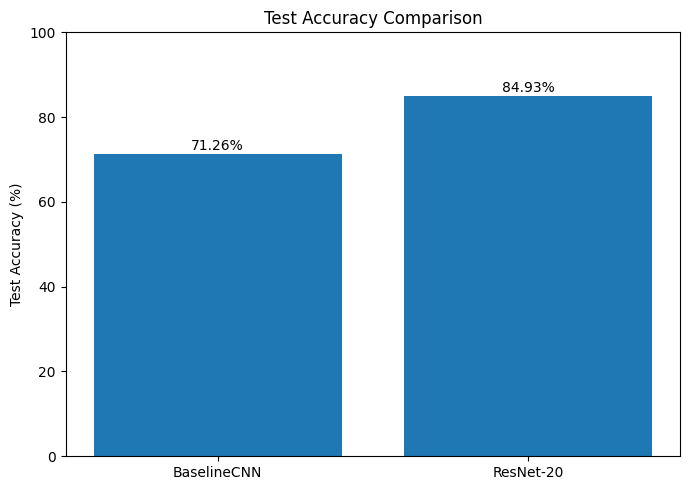

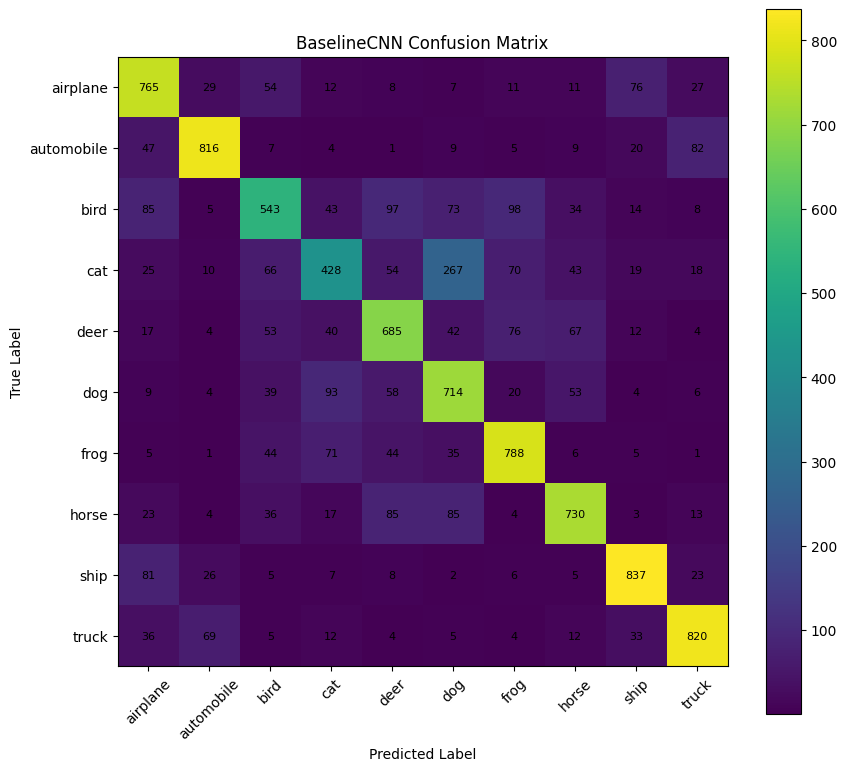


对比表、准确率对比图和 BaselineCNN 混淆矩阵图片已保存！


In [20]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import confusion_matrix

# 1. 整理两个模型的测试指标
comparison = pd.DataFrame([
    {
        "Model": "BaselineCNN",
        "Epochs": 20,
        "Test Loss": 0.8301,
        "Test Accuracy (%)": 71.26,
        "Macro Precision (%)": 71.19,
        "Macro Recall (%)": 71.26,
        "Macro F1 (%)": 70.95
    },
    {
        "Model": "ResNet-20",
        "Epochs": 20,
        "Test Loss": 0.4481,
        "Test Accuracy (%)": 84.93,
        "Macro Precision (%)": 84.95,
        "Macro Recall (%)": 84.93,
        "Macro F1 (%)": 84.91
    }
])

# 2. 保存对比表
comparison.to_csv(
    os.path.join(RESULT_DIR, "model_comparison.csv"),
    index=False
)

print("模型对比表：")
display(comparison)

# 3. 绘制测试准确率对比图
plt.figure(figsize=(7, 5))

bars = plt.bar(
    comparison["Model"],
    comparison["Test Accuracy (%)"]
)

plt.title("Test Accuracy Comparison")
plt.ylabel("Test Accuracy (%)")
plt.ylim(0, 100)

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 1,
        f"{height:.2f}%",
        ha="center"
    )

plt.tight_layout()

plt.savefig(
    os.path.join(RESULT_DIR, "model_comparison_accuracy.png"),
    dpi=300
)

plt.show()

# 4. 生成 BaselineCNN 混淆矩阵图片
class_names = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck"
]

cm_baseline = confusion_matrix(
    all_labels_baseline,
    all_predictions_baseline
)

plt.figure(figsize=(9, 8))
plt.imshow(cm_baseline, interpolation="nearest")
plt.title("BaselineCNN Confusion Matrix")
plt.colorbar()

plt.xticks(range(10), class_names, rotation=45)
plt.yticks(range(10), class_names)
plt.xlabel("Predicted Label")
plt.ylabel("True Label")

for i in range(10):
    for j in range(10):
        plt.text(
            j, i, str(cm_baseline[i, j]),
            ha="center", va="center", fontsize=8
        )

plt.tight_layout()

plt.savefig(
    os.path.join(RESULT_DIR, "baseline20_confusion_matrix.png"),
    dpi=300
)

plt.show()

print("\n对比表、准确率对比图和 BaselineCNN 混淆矩阵图片已保存！")

In [21]:
print("项目文件检查：")

files_to_check = [
    "checkpoints/baseline_best.pth",
    "checkpoints/baseline20_best.pth",
    "checkpoints/resnet20_best.pth",
    "results/baseline_training_log.csv",
    "results/baseline20_training_log.csv",
    "results/resnet20_training_log.csv",
    "results/baseline20_test_result.csv",
    "results/resnet20_test_result.csv",
    "results/baseline20_classification_report.txt",
    "results/resnet20_classification_report.txt",
    "results/baseline20_confusion_matrix.png",
    "results/resnet20_confusion_matrix.png",
    "results/model_comparison.csv",
    "results/model_comparison_accuracy.png"
]

for file in files_to_check:
    path = os.path.join(PROJECT_DIR, file)
    status = "已存在" if os.path.exists(path) else "缺失"
    print(f"{status}: {file}")

项目文件检查：
已存在: checkpoints/baseline_best.pth
已存在: checkpoints/baseline20_best.pth
已存在: checkpoints/resnet20_best.pth
已存在: results/baseline_training_log.csv
已存在: results/baseline20_training_log.csv
已存在: results/resnet20_training_log.csv
已存在: results/baseline20_test_result.csv
已存在: results/resnet20_test_result.csv
已存在: results/baseline20_classification_report.txt
已存在: results/resnet20_classification_report.txt
已存在: results/baseline20_confusion_matrix.png
已存在: results/resnet20_confusion_matrix.png
已存在: results/model_comparison.csv
已存在: results/model_comparison_accuracy.png


In [22]:
import torch
import os

# 1. 加载 BaselineCNN（20 Epoch）
baseline_check = BaselineCNN().to(device)

baseline_check.load_state_dict(
    torch.load(
        os.path.join(MODEL_DIR, "baseline20_best.pth"),
        map_location=device
    )
)

baseline_check.eval()

# 2. 加载 ResNet-20
resnet_check = ResNet20().to(device)

resnet_check.load_state_dict(
    torch.load(
        os.path.join(MODEL_DIR, "resnet20_best.pth"),
        map_location=device
    )
)

resnet_check.eval()

print("两个模型的权重均加载成功！")

# 3. 使用测试集中的一批图片进行预测
images, labels = next(iter(test_loader))

images = images[:8].to(device)
labels = labels[:8]

with torch.no_grad():
    baseline_outputs = baseline_check(images)
    resnet_outputs = resnet_check(images)

    baseline_predictions = baseline_outputs.argmax(dim=1)
    resnet_predictions = resnet_outputs.argmax(dim=1)

print("\n输出形状：")
print("BaselineCNN：", baseline_outputs.shape)
print("ResNet-20：", resnet_outputs.shape)

print("\n前8张图片的真实标签：")
print(labels.tolist())

print("\nBaselineCNN 预测结果：")
print(baseline_predictions.cpu().tolist())

print("\nResNet-20 预测结果：")
print(resnet_predictions.cpu().tolist())

print("\n模型加载与预测检查完成！")

两个模型的权重均加载成功！

输出形状：
BaselineCNN： torch.Size([8, 10])
ResNet-20： torch.Size([8, 10])

前8张图片的真实标签：
[3, 8, 8, 0, 6, 6, 1, 6]

BaselineCNN 预测结果：
[3, 8, 8, 0, 6, 6, 1, 6]

ResNet-20 预测结果：
[3, 8, 8, 8, 6, 6, 1, 2]

模型加载与预测检查完成！
